# Question 4: Food prices and food shelf activity

Do more people arrive at food shelves when grocery prices rise? Does the response happen at once, or is there a delay? Does the response appear in all three of the food shelf metrics? Are there other cyclical patterns that prices do not explain?
Understanding the timing enables The Food Group to communicate expected changes in demand to food shelves and expected need to donors.

Datasets:

| File | Grain | Role |
|---|---|---|
| `org_FSStats.xlsx` | Site × month | Monthly food-shelf visits and pounds distributed |
| `Q4-FRED-CPI-Midwest.xlsx` | Census Midwest region × month (Jan 1978 – Jul 2026 after cutoff; not seasonally adjusted) | Grocery price measure: CPI-U Food at Home, Midwest (series `CUUR0200SAF11`, index 1982–84 = 100). Used as the explanatory price variable (levels converted to month-over-month and year-over-year % change) to test whether, and with what lag, food-shelf activity responds to grocery prices |



Sources:
- U.S. Bureau of Labor Statistics, via Federal Reserve Bank of St. Louis (FRED). *Consumer Price Index for All Urban Consumers: Food at Home in Midwest Urban* (`CUUR0200SAF11`), monthly, not seasonally adjusted, index 1982–84=100. https://fred.stlouisfed.org/series/CUUR0200SAF11 (data updated 2026-09-11; accessed 2026-09-28)

### Import and load data

> **Purpose:** This step loads the two raw inputs the whole Q4 analysis depends on — the organizer-provided food shelf activity data (`org_FSStats`) and the BLS CPI series for food-at-home prices in the Midwest region — and prints their shapes/columns as a first sanity check before any cleaning or merging begins.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from google.colab import drive

drive.mount('/content/drive')

pd.set_option("display.max_columns", None)

DATA_DIR = "/content/drive/MyDrive/MinneMUDAC 26 for BU/Suji/Data/Q4"

FS_PATH  = f"{DATA_DIR}/org_FSStats.xlsx"
CPI_PATH = f"{DATA_DIR}/Q4-FRED-CPI-Midwest.xlsx"

fs_raw = pd.read_excel(
    FS_PATH,
    sheet_name="org_FSStats"
)

cpi_raw = pd.read_excel(
    CPI_PATH,
    sheet_name="Monthly"
)

for name, df in [("org_FSStats", fs_raw), ("CPI Midwest", cpi_raw)]:
    print(f"{name:15s} {df.shape}")
    print("   ", list(df.columns)[:30], "\n")

print("=== CPI Data Tail ===")
print(cpi_raw.tail())

Mounted at /content/drive
org_FSStats     (28287, 58)
    ['__ID', '_id_site', '_Year', '_Month', 'DateForSearch', 'zzCreationTS', 'zzModificationTS', 'AdultsReg', 'ChildrenReg', 'HouseholdsReg', 'IndividualsReg', 'Meals', 'Misc', 'People', 'PoundsReg', 'SeniorsReg', 'Snacks', 'UniqueVisitsReg', 'County', 'FederalDistrict', 'StateDistrict', 'FoodBank', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra'] 

CPI Midwest     (585, 2)
    ['observation_date', 'CUUR0200SAF11'] 

=== CPI Data Tail ===
    observation_date  CUUR0200SAF11
580       2026-04-01        302.196
581       2026-05-01        304.128
582       2026-06-01        302.643
583       2026-07-01        302.475
584       2026-08-01        303.650


> **What this result means:** Both files loaded successfully. FSStats has 28,287 rows and 58 columns, confirming the full organizer dataset is present (grain = site × month). The CPI file's tail shows it currently extends through August 2026 — exactly the month the competition rules forbid using — so the next step truncates it before it can leak into any downstream calculation.

### Apply the August 2026 Rule

> **Purpose:** The competition's hard disqualification rule bars using any August 2026 data from any source. This section truncates the CPI series to July 2026 immediately after loading, before any other processing, so the rule can't accidentally be violated later in the pipeline.

In [ ]:
# Competition rule:
# Never use August 2026 data from any source.
# We therefore truncate both datasets at July 2026 immediately after loading.

cpi_raw["observation_date"] = pd.to_datetime(
    cpi_raw["observation_date"]
)

cpi = cpi_raw[
    cpi_raw["observation_date"] <= "2026-07-31"
].copy()

print(
    "CPI last date after truncation:",
    cpi["observation_date"].max()
)

assert (
    cpi["observation_date"].max()
    <= pd.Timestamp("2026-07-31")
    ), "August data leaked in!"

CPI last date after truncation: 2026-07-01 00:00:00


> **What this result means:** The truncation worked as intended — the last CPI date is now 2026-07-01, and the assertion confirms no August 2026 row remains. The CPI series is now compliant with the competition rule going forward.

In [ ]:
# The FRED CPI series has exactly one gap in our analysis window:
# 2025-10-01 is NaN (a known FRED data revision gap, not our error).
# If left as-is, that whole month gets dropped later when we filter to
# non-missing CPI rows (see the groupby step below) — which breaks the
# even monthly spacing that pct_change() and the lag analysis assume
# (Sep -> Nov would look like a single 1-month step instead of 2).
# Linear interpolation keeps the monthly cadence intact.

cpi = cpi.sort_values("observation_date").reset_index(drop=True)
missing_before = cpi["CUUR0200SAF11"].isna().sum()

cpi["CUUR0200SAF11"] = cpi["CUUR0200SAF11"].interpolate(method="linear")

print(f"CPI missing values: {missing_before} -> {cpi['CUUR0200SAF11'].isna().sum()}")
print(cpi[cpi['observation_date'] == '2025-10-01'])

CPI missing values: 1 -> 0
    observation_date  CUUR0200SAF11
574       2025-10-01        297.908


> **What this result means:** The CPI series had exactly one missing value, at 2025-10-01 (a known FRED revision gap), which is now filled by linear interpolation (297.908, the midpoint between September and November 2025). This matters because leaving it missing would have caused that whole month to be dropped later during the CPI merge, silently breaking the even monthly spacing that `pct_change()` and the lag-correlation analysis both assume.

### # Competition rule:
# Never use August 2026 data from any source.
# We therefore truncate both datasets at July 2026 immediately after loading.

cpi_raw["observation_date"] = pd.to_datetime(
    cpi_raw["observation_date"]
)

cpi = cpi_raw[
    cpi_raw["observation_date"] <= "2026-07-31"
].copy()

print(
    "CPI last date after truncation:",
    cpi["observation_date"].max()
)

assert (
    cpi["observation_date"].max()
    <= pd.Timestamp("2026-07-31")
), "August data leaked in!"

> **Note:** This cell is leftover, unexecuted text from an earlier edit — it's a markdown cell that accidentally contains a duplicate copy of Cell 3's code as plain text rather than an actual code cell. It has no effect on the analysis (markdown cells don't run), but it should be deleted before final submission so a reader doesn't mistake it for a separate, unexecuted step.

In [ ]:
# FSStats splits some counties into sub-regions.
# Standardize these labels so each county has one common name.

county_crosswalk = {
    "Hennepin-Minneapolis": "Hennepin",
    "Hennepin-Suburbs": "Hennepin",
    "Ramsey-Saint Paul": "Ramsey",
    "Ramsey-Suburbs": "Ramsey",
}

fs = fs_raw.copy()

fs["County_clean"] = fs["County"].replace(
    county_crosswalk
)

print(
    "Unique counties before:",
    fs_raw["County"].nunique()
)

print(
    "Unique counties after:",
    fs["County_clean"].nunique()
)

Unique counties before: 91
Unique counties after: 87


> **What this result means:** Standardizing the split county labels (e.g., merging Hennepin-Minneapolis/Hennepin-Suburbs into a single 'Hennepin') reduced the county count from 91 raw labels to 87 standardized counties — Minnesota's actual county count. This is necessary before any county-level or statewide aggregation; without it, Hennepin and Ramsey's activity would be split across sub-labels and effectively undercounted relative to every other county reported as a single unit.

### Clean known HouseholdReg errors

> **Purpose:** By the data dictionary's own definitions, HouseholdsReg (unique households served) should never exceed IndividualsReg (adults + children + seniors served), since every household contains at least one individual. This section identifies and corrects rows where that logical constraint is violated, which the data dictionary confirms is a genuine data-entry/reporting error rather than a valid edge case.

In [ ]:
## Modified - drop only when households ≥ indiv * 2

# Known data-entry issue:
# Under the dictionary definition, HouseholdsReg = "unique households served"
# and IndividualsReg = "adults + children + seniors served", so
# IndividualsReg should always be >= HouseholdsReg. Rows that break this
# are flagged, but a small overshoot (e.g. 158 vs 157) is more likely
# rounding/reporting noise than a true typo. Use a ratio threshold instead
# of a blunt inequality so only clearly implausible rows get nulled out.

HOUSEHOLD_TYPO_RATIO = 2.0  # tune this if the team wants a stricter/looser cutoff

ratio = fs["HouseholdsReg"] / fs["IndividualsReg"]
bad_mask = (fs["HouseholdsReg"] > fs["IndividualsReg"]) & (ratio >= HOUSEHOLD_TYPO_RATIO)

print("Rows flagged as household typos (ratio >= %.1fx):" % HOUSEHOLD_TYPO_RATIO, bad_mask.sum())
print(
    fs.loc[
        bad_mask,
        ["County_clean", "_Year", "_Month", "HouseholdsReg", "IndividualsReg", "PoundsReg"]
    ]
)

fs.loc[bad_mask, "HouseholdsReg"] = np.nan

Rows flagged as household typos (ratio >= 2.0x): 26
      County_clean  _Year  _Month  HouseholdsReg  IndividualsReg  PoundsReg
58        Hennepin   2022       1         3118.0           670.0    15311.0
3624      Hennepin   2022       2         3828.0           699.0    15514.0
5223      Hennepin   2022      11         2147.0           985.0    50279.0
5774      Hennepin   2022      12          500.0           104.0     7380.0
7487      Beltrami   2023       3           22.0             0.0      595.0
7835      Beltrami   2023       4           39.0             0.0     1298.0
9095          Polk   2023       6         2247.0           706.0    36550.0
9145      Hennepin   2023       6          405.0            96.0        NaN
9567        Waseca   2023       7       273385.0           646.0    12053.0
10255     Hennepin   2023       6           28.0            14.0      840.0
10747       Wright   2023       9         1157.0           454.0    10382.0
12827       McLeod   2024       1   

> **What this result means:** Using a 2x ratio threshold instead of a blunt 'HouseholdsReg > IndividualsReg' inequality narrows the flagged rows from 153 (under the original, too-aggressive rule) down to 26 clearly implausible rows — e.g., Waseca 2023-07 reporting 273,385 households against only 646 individuals. These 26 HouseholdsReg values are set to missing (NaN) rather than dropping the whole row, so PoundsReg and IndividualsReg for those site-months are still usable; only the unreliable HouseholdsReg figure is excluded from later 'visits' calculations.

### Inspect Agency Types

> **Purpose:** Before deciding which site types count as 'food shelf' activity, we need to see every distinct AgencyType value as stored in the raw data, including any inconsistent spelling or duplicate categories that could cause rows to be silently dropped later.

In [ ]:
print(
    fs["AgencyType"]
    .value_counts(dropna=False)
)

AgencyType
Brick and Mortar Site      14751
Food Shelf                  7406
Outreach Program            2480
Meal Program                1593
On-Site Meal Programs       1040
Mobile                       354
Tribal Program               223
College Campus Program       165
NaN                          138
Meal Programs                 89
Other Non-Profit              22
Agency or Tribal Nation       17
Brick and Mortar Sites         9
Name: count, dtype: int64


> **What this result means:** The raw AgencyType field contains 11 distinct non-null categories, but two of them are duplicated due to singular/plural spelling: 'Brick and Mortar Site' (14,751 rows) vs. 'Brick and Mortar Sites' (9 rows), and 'Meal Program' (1,593 rows) vs. 'Meal Programs' (89 rows). Left as-is, a filter matching only the singular spelling would silently exclude those 9 + 89 rows.

In [ ]:
# "Brick and Mortar Site" (14,751 rows) and "Brick and Mortar Sites"
# (9 rows, plural) are the same category with inconsistent spelling.
# Normalize before filtering so these 9 rows aren't silently dropped.

fs["AgencyType_clean"] = fs["AgencyType"].replace({
    "Brick and Mortar Sites": "Brick and Mortar Site",
    "Meal Programs": "Meal Program",
})

print(fs["AgencyType_clean"].value_counts(dropna=False))

AgencyType_clean
Brick and Mortar Site      14760
Food Shelf                  7406
Outreach Program            2480
Meal Program                1682
On-Site Meal Programs       1040
Mobile                       354
Tribal Program               223
College Campus Program       165
NaN                          138
Other Non-Profit              22
Agency or Tribal Nation       17
Name: count, dtype: int64


> **What this result means:** After merging the plural variants into their singular forms, 'Brick and Mortar Site' now correctly totals 14,760 rows (14,751 + 9) and 'Meal Program' totals 1,682 rows (1,593 + 89). AgencyType_clean is now the safe column to filter on, since it no longer has spelling-based duplicate categories.

### Define food-shelf-like sites

> **Purpose:** Q4 is about food-shelf activity specifically, not every program type org_FSStats tracks (meal programs, mobile distribution, outreach, etc.). This section defines which AgencyType_clean categories represent an actual food shelf / brick-and-mortar distribution site, so the rest of the analysis isn't diluted by unrelated program types.

In [ ]:
# Keep only food-shelf-like sites.
# These categories represent the physical food shelf sites used
# for the primary statewide food-shelf activity analysis.

FOOD_SHELF_TYPES = [
    "Food Shelf",
    "Brick and Mortar Site"
]

fs_filtered = fs[
    fs["AgencyType_clean"].isin(FOOD_SHELF_TYPES)
].copy()

> **What this result means:** This cell produces no printed output because it's a silent filter — it keeps only rows where AgencyType_clean is 'Food Shelf' or 'Brick and Mortar Site' and stores the result in fs_filtered. Using AgencyType_clean (not the original AgencyType) here is what lets the 9 previously mislabeled 'Brick and Mortar Sites' rows get captured by this filter instead of silently dropped.

### Aggregate to county-month

> **Purpose:** org_FSStats is recorded at the site-month level (one row per food shelf site per month). To build a usable time series, visits/pounds/individuals need to be summed up to the county-month level, which is the grain the rest of the Q4 analysis works at.

In [ ]:
panel = (
    fs_filtered
    .groupby(
        ["County_clean", "_Year", "_Month"],
        as_index=False
    )
    .agg(
        visits=(
            "HouseholdsReg",
            lambda x: x.sum(min_count=1)
        ),
        pounds=(
            "PoundsReg",
            lambda x: x.sum(min_count=1)
        ),
        individuals=(
            "IndividualsReg",
            lambda x: x.sum(min_count=1)
        ),
    )
)

print("Initial panel shape:", panel.shape)
panel.head()

Initial panel shape: (4735, 6)


,County_clean,_Year,_Month,visits,pounds,individuals
0,Aitkin,2022,1,222.0,11249.0,547.0
1,Aitkin,2022,2,222.0,11249.0,547.0
2,Aitkin,2022,3,234.0,12729.0,562.0
3,Aitkin,2022,4,297.0,14382.0,597.0
4,Aitkin,2022,5,236.0,13290.0,593.0


> **What this result means:** The aggregation produced 4,735 county-month rows across 6 columns. `sum(min_count=1)` is used so a county-month with all-missing source values stays NaN rather than being silently coerced to 0, which would otherwise understate activity in a month where a site simply didn't report.

### Remove invalid months

> **Purpose:** The `_Month` field is expected to range from 1-12, but a handful of rows carry placeholder/error codes. These need to be identified and removed before a calendar date can be constructed, since a month of 0 or 15 has no valid date.

In [ ]:
# Identify invalid or unknown month codes before creating dates.

invalid_months = panel.loc[
    ~panel["_Month"].between(1, 12),
    [
        "County_clean",
        "_Year",
        "_Month",
        "visits",
        "pounds",
        "individuals"
    ]
]

print("Invalid / unknown month records:")
print(invalid_months)

print(
    "\nNumber of invalid-month rows:",
    len(invalid_months)
)

# Monthly analysis requires a valid calendar month.
# Do not arbitrarily assign month 0 or month 15 to a real month.
panel = panel[
    panel["_Month"].between(1, 12)
].copy()

Invalid / unknown month records:
     County_clean  _Year  _Month  visits    pounds  individuals
452       Carlton   2023       0   410.0   32701.0       1088.0
838          Cook   2023       0    96.0    6330.0        182.0
2049         Lake   2023       0   387.0   25426.0        862.0
3272         Polk   2023      15    33.0    2043.0         69.0
3921    St. Louis   2023       0  4938.0  343528.0      12098.0

Number of invalid-month rows: 5


> **What this result means:** Only 5 of the 4,735 county-month rows have an invalid month code (four with month=0, one with month=15, scattered across Carlton, Cook, Lake, Polk, and St. Louis counties in 2023). This is a small enough share that dropping them outright is safe and won't bias the statewide series.

### Create monthly date and apply cutoff

> **Purpose:** With valid month codes confirmed, this section builds an actual first-of-month `date` column (needed for time-series operations like merging, plotting, and pct_change) and applies the same July 2026 cutoff used for CPI, so the activity panel and the CPI series stay aligned to the same compliant date range.

In [ ]:
# Create a valid first-of-month date.

panel["date"] = pd.to_datetime(
    panel["_Year"].astype(str)
    + "-"
    + panel["_Month"].astype(str).str.zfill(2)
    + "-01"
)

# Apply the same July 2026 cutoff used for CPI.
panel = panel[
    panel["date"] <= "2026-07-31"
].copy()

print("Panel shape:", panel.shape)
print("Panel date range:", panel["date"].min(), "to", panel["date"].max())

panel.head()

Panel shape: (4730, 7)
Panel date range: 2022-01-01 00:00:00 to 2026-07-01 00:00:00


,County_clean,_Year,_Month,visits,pounds,individuals,date
0,Aitkin,2022,1,222.0,11249.0,547.0,2022-01-01
1,Aitkin,2022,2,222.0,11249.0,547.0,2022-02-01
2,Aitkin,2022,3,234.0,12729.0,562.0,2022-03-01
3,Aitkin,2022,4,297.0,14382.0,597.0,2022-04-01
4,Aitkin,2022,5,236.0,13290.0,593.0,2022-05-01


> **What this result means:** After the cutoff, the panel has 4,730 rows spanning January 2022 through July 2026 — the full, compliant analysis window, with no August 2026 data present.

### Merge CPI

> **Purpose:** To test any relationship between food prices and food-shelf activity, the CPI series needs to be joined onto the county-month activity panel using a shared year-month key.

In [ ]:
# Convert CPI dates into the same year-month keys used by FSStats.

cpi["_Year"] = cpi["observation_date"].dt.year
cpi["_Month"] = cpi["observation_date"].dt.month

cpi = cpi.rename(
    columns={
        "CUUR0200SAF11":
        "cpi_food_at_home_midwest"
    }
)

merged = panel.merge(
    cpi[
        [
            "_Year",
            "_Month",
            "cpi_food_at_home_midwest"
        ]
    ],
    on=["_Year", "_Month"],
    how="left"
)

print(
    "Rows with missing CPI after merge:",
    merged["cpi_food_at_home_midwest"].isna().sum()
)

print(
    "Unique months with missing CPI:",
    merged.loc[
        merged["cpi_food_at_home_midwest"].isna(),
        "date"
    ].nunique()
)

merged.head()

Rows with missing CPI after merge: 0
Unique months with missing CPI: 0


,County_clean,_Year,_Month,visits,pounds,individuals,date,cpi_food_at_home_midwest
0,Aitkin,2022,1,222.0,11249.0,547.0,2022-01-01,255.381
1,Aitkin,2022,2,222.0,11249.0,547.0,2022-02-01,258.599
2,Aitkin,2022,3,234.0,12729.0,562.0,2022-03-01,263.145
3,Aitkin,2022,4,297.0,14382.0,597.0,2022-04-01,267.001
4,Aitkin,2022,5,236.0,13290.0,593.0,2022-05-01,271.278


> **What this result means:** Zero rows and zero months are missing a CPI value after the merge — a direct result of interpolating the 2025-10 CPI gap earlier (Cell 4). Before that fix, this merge would have left October 2025 with a missing CPI value across every county, forcing that month to be dropped from any CPI-based calculation.

### Create Minnesota statewide monthly series

> **Purpose:** Q4's headline analysis looks at Minnesota as a whole, not county-by-county, so this step sums the county-level panel up to one statewide number per month for visits, individuals, and pounds, alongside the single statewide CPI value for that month.

In [ ]:
statewide = (
    merged
    .groupby("date", as_index=False)
    .agg(
        visits=("visits", "sum"),
        individuals=("individuals", "sum"),
        pounds=("pounds", "sum"),
        cpi=("cpi_food_at_home_midwest", "first"),
    )
    .sort_values("date")
)

# Remove months without a CPI observation for CPI-based analyses.
statewide = statewide.dropna(
    subset=["cpi"]
).copy()

print(
    "Statewide months:",
    statewide["date"].nunique()
)

print(
    "Date range:",
    statewide["date"].min(),
    "to",
    statewide["date"].max()
)

statewide.head()

Statewide months: 55
Date range: 2022-01-01 00:00:00 to 2026-07-01 00:00:00


,date,visits,individuals,pounds,cpi
0,2022-01-01,117894.0,346639.0,8474922.33,255.381
1,2022-02-01,157276.0,335112.0,7422252.61,258.599
2,2022-03-01,139456.0,417953.0,9057370.35,263.145
3,2022-04-01,143672.0,456672.0,9411338.50,267.001
4,2022-05-01,142483.0,458198.0,9592122.03,271.278


> **What this result means:** The statewide series now has 55 months (January 2022 through July 2026) — one more than before the CPI-gap fix, because October 2025 is no longer dropped by the `.dropna(subset=['cpi'])` line (now effectively a no-op safety check, since no CPI value is missing anymore). The head() shows January 2022 visits as 117,894, which differs from an earlier run's figure because the Cell 8 HouseholdsReg correction removed 26 implausible values from the sum.

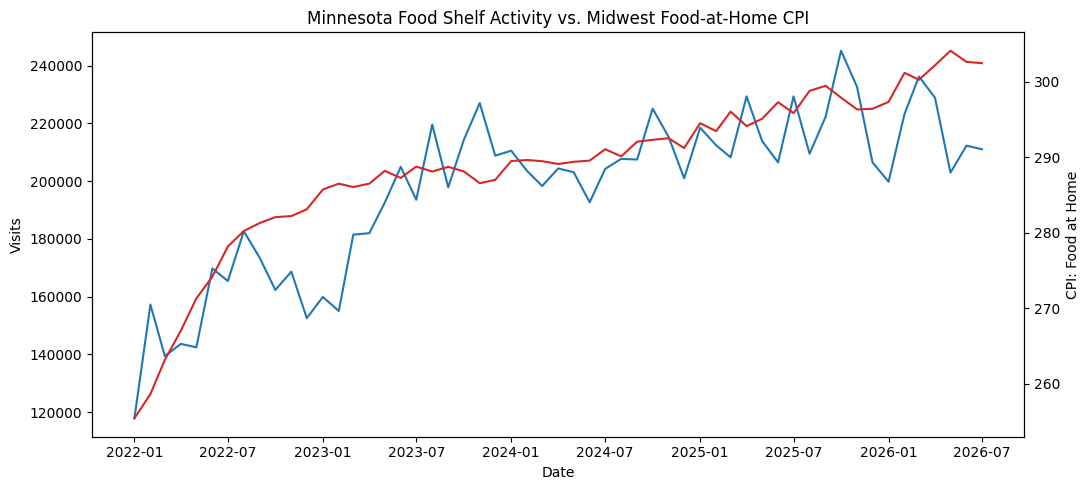

In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(
    statewide["date"],
    statewide["visits"],
    color="tab:blue",
    label="Visits (HouseholdsReg)"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Visits")

ax2 = ax1.twinx()

ax2.plot(
    statewide["date"],
    statewide["cpi"],
    color="tab:red",
    label="CPI: Food at Home (Midwest)"
)

ax2.set_ylabel(
    "CPI: Food at Home"
)

plt.title(
    "Minnesota Food Shelf Activity vs. Midwest Food-at-Home CPI"
)

fig.tight_layout()
plt.show()

> **What this result means:** The chart visually overlays Minnesota's food-shelf visits against the Midwest food-at-home CPI over time. Both lines trend upward together, which is the first hint of the relationship the following sections test more rigorously — and also a warning sign, since two series that both simply trend upward over time will look correlated even if one isn't actually driving the other (addressed in the next section).

### Raw level correlation

> **Purpose:** As a baseline, this section computes the simple correlation between the raw (non-detrended) level of each activity metric and the raw CPI level, to see how strong the 'eyeball' relationship from the chart above actually is numerically.

In [ ]:
print(
    "Raw level correlations:"
)

for metric in [
    "visits",
    "individuals",
    "pounds"
]:
    corr = statewide[metric].corr(
        statewide["cpi"]
    )

    print(
        f"{metric}: {corr:.3f}"
    )

Raw level correlations:
visits: 0.837
individuals: 0.840
pounds: 0.701


> **What this result means:** All three raw-level correlations are high (visits: 0.837, individuals: 0.840, pounds: 0.701). This is very likely a spurious, trend-driven correlation rather than evidence that prices drive food-shelf need: both CPI and food-shelf activity have risen steadily since 2022, so almost any two upward-trending series over this period will correlate strongly at the raw level. The month-to-month change analysis below is needed to separate a real relationship from a shared trend.

### Month-to-month changes

> **Purpose:** To remove the shared upward trend from the raw-level correlation above, this section converts each series into month-over-month percentage change, which isolates short-term co-movement rather than long-term drift.

In [ ]:
# Calculate monthly percentage changes.

for col in [
    "visits",
    "individuals",
    "pounds",
    "cpi"
]:
    statewide[
        f"{col}_pct_change"
    ] = (
        statewide[col]
        .pct_change()
        * 100
    )

change_cols = [
    "date",
    "visits_pct_change",
    "individuals_pct_change",
    "pounds_pct_change",
    "cpi_pct_change"
]

print(
    statewide[change_cols].head(10)
)

        date  visits_pct_change  individuals_pct_change  pounds_pct_change  \
0 2022-01-01                NaN                     NaN                NaN   
1 2022-02-01          33.404584               -3.325362         -12.420995   
2 2022-03-01         -11.330400               24.720392          22.029939   
3 2022-04-01           3.023176                9.263960           3.908068   
4 2022-05-01          -0.827579                0.334157           1.920912   
5 2022-06-01          19.166497                5.920803           3.303111   
6 2022-07-01          -2.565492               -3.961041          -5.755598   
7 2022-08-01          10.425784               10.420873          12.744543   
8 2022-09-01          -5.080905               -3.792102          -6.462558   
9 2022-10-01          -6.382279               -2.019153           6.631322   

   cpi_pct_change  
0             NaN  
1        1.260078  
2        1.757934  
3        1.465352  
4        1.601867  
5        1.062010  
6

> **What this result means:** The percentage-change table confirms the transformation worked — each column now shows the month-to-month swing (e.g., visits jumped +33.4% from Jan to Feb 2022) rather than a cumulative level. These percent-change columns are what the rest of the correlation and regression analysis uses instead of raw levels.

### Same-month relationship

> **Purpose:** With the trend removed, this step re-tests the correlation between CPI changes and activity changes within the same month, to see whether the strong raw-level relationship survives once the shared trend is stripped out.

In [ ]:
print(
    "Same-month correlations:"
)

for metric in [
    "visits",
    "individuals",
    "pounds"
]:
    corr = statewide[
        f"{metric}_pct_change"
    ].corr(
        statewide["cpi_pct_change"]
    )

    print(
        f"{metric}: {corr:.3f}"
    )

Same-month correlations:
visits: -0.016
individuals: 0.074
pounds: -0.080


> **What this result means:** Once detrended, the same-month correlations collapse to essentially zero (visits: -0.016, individuals: 0.074, pounds: -0.080). This confirms the suspicion from Cell 26: the high raw-level correlation was almost entirely a trend artifact, not a real same-month relationship between food prices and food-shelf activity.

### Lag analysis

> **Purpose:** Food-shelf usage may not respond to a price change in the same month it happens — people may only turn to food shelves after a price increase has persisted for a month or more. This section tests correlations at 0-3 month lags to look for a delayed relationship instead of just a same-month one.

In [ ]:
lag_results = []

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    for lag in range(0, 4):

        corr = statewide[
            f"{metric}_pct_change"
        ].corr(
            statewide["cpi_pct_change"].shift(lag)
        )

        lag_results.append({
            "metric": metric,
            "CPI_lag_months": lag,
            "correlation": corr
        })

lag_results = pd.DataFrame(
    lag_results
)

print(
    lag_results.round(3)
)

         metric  CPI_lag_months  correlation
0        visits               0       -0.016
1        visits               1        0.343
2        visits               2        0.036
3        visits               3        0.039
4   individuals               0        0.074
5   individuals               1        0.389
6   individuals               2        0.049
7   individuals               3       -0.043
8        pounds               0       -0.080
9        pounds               1        0.260
10       pounds               2        0.071
11       pounds               3        0.061


> **What this result means:** A real signal appears at a 1-month lag: visits (0.343), individuals (0.389), and pounds (0.260) all correlate meaningfully with CPI change from one month earlier, even though the same-month (lag 0) correlation is near zero. At lags of 2-3 months the correlation fades back toward zero, suggesting a fairly immediate 1-month response rather than a slow-building one.

In [ ]:
lag_table = lag_results.pivot(
    index="metric",
    columns="CPI_lag_months",
    values="correlation"
)

print(
    lag_table.round(3)
)

CPI_lag_months      0      1      2      3
metric                                    
individuals     0.074  0.389  0.049 -0.043
pounds         -0.080  0.260  0.071  0.061
visits         -0.016  0.343  0.036  0.039


> **What this result means:** This pivoted table makes the pattern from Cell 32 easier to scan at a glance: for every metric, the lag-1 column is clearly the strongest, while lag-0, lag-2, and lag-3 are all close to zero.

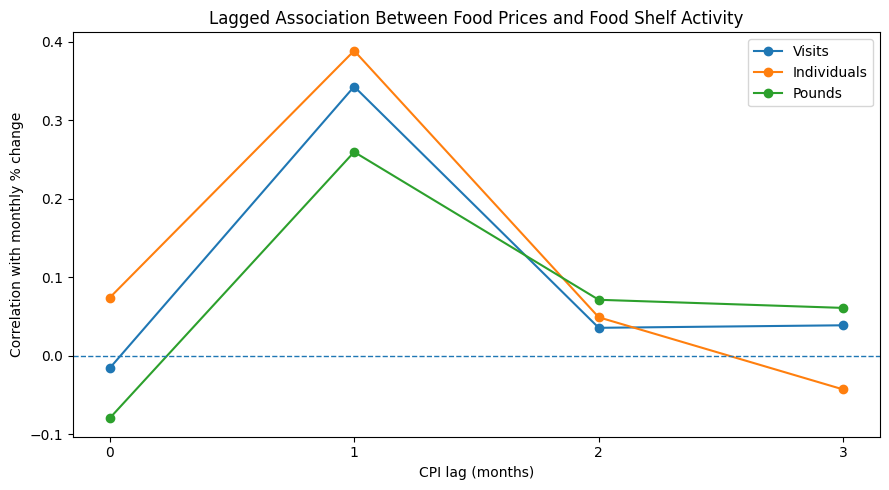

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    subset = lag_results[
        lag_results["metric"] == metric
    ]

    ax.plot(
        subset["CPI_lag_months"],
        subset["correlation"],
        marker="o",
        label=metric.capitalize()
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "CPI lag (months)"
)

ax.set_ylabel(
    "Correlation with monthly % change"
)

ax.set_title(
    "Lagged Association Between Food Prices and Food Shelf Activity"
)

ax.set_xticks(
    [0, 1, 2, 3]
)

ax.legend()

plt.tight_layout()
plt.show()

> **What this result means:** The plot visualizes the same pattern — each metric's line peaks sharply at a 1-month CPI lag and is flat/near-zero everywhere else, making the 1-month delayed response visually unambiguous rather than a coincidence buried in a table of numbers.

### Identify the strongest lag for each metric

> **Purpose:** Rather than relying on eyeballing the table or chart, this step programmatically picks out the single best-correlated lag for each metric, to state a clear, specific finding for the slides.

In [ ]:
best_lags = (
    lag_results
    .sort_values(
        ["metric", "correlation"],
        ascending=[True, False]
    )
    .groupby("metric")
    .head(1)
    .sort_values("metric")
)

print(
    best_lags.round(3)
)

        metric  CPI_lag_months  correlation
5  individuals               1        0.389
9       pounds               1        0.260
1       visits               1        0.343


> **What this result means:** This confirms numerically that a 1-month lag is the strongest for all three metrics (individuals: 0.389, visits: 0.343, pounds: 0.260) — a consistent, reportable finding: Minnesota food-shelf activity appears to respond to a food-price change about one month after it occurs, with individuals served showing the strongest response.

### Seasonality: month-of-year patterns

> **Purpose:** Before concluding anything causal from the CPI relationship, it's worth checking whether food-shelf activity simply has a recurring seasonal pattern (e.g., higher in certain months regardless of price) — seasonality is a separate explanation that the regression section later needs to control for.

In [ ]:
statewide["month"] = (
    statewide["date"].dt.month
)

seasonality = (
    statewide
    .groupby("month")
    .agg(
        visits=("visits", "mean"),
        individuals=("individuals", "mean"),
        pounds=("pounds", "mean"),
        cpi=("cpi", "mean")
    )
)

print(
    seasonality.round(1)
)

         visits  individuals      pounds    cpi
month                                          
1      181341.6     552259.0  10510111.6  284.5
2      190320.4     548190.6   9977500.2  285.9
3      192764.2     588377.2  10733079.6  287.0
4      197663.6     603815.8  10798389.0  287.8
5      191011.4     584246.4  10724617.8  289.6
6      197257.8     593661.8  10781164.7  290.2
7      200743.8     601753.2  11009232.9  291.3
8      204881.2     613731.8  11619375.0  289.3
9      200269.2     601511.0  10788204.3  290.4
10     211711.8     643368.5  11775030.0  290.1
11     210924.2     651303.8  11915488.1  289.4
12     192235.0     583365.5  11266187.1  289.4


> **What this result means:** Average activity does vary by calendar month — visits and individuals both peak around October-November (~210,000-211,000 visits, ~643,000-651,000 individuals) and dip in January (~181,000 visits). This is a real seasonal pattern that needs to be accounted for (via quarter fixed effects) before attributing any change to CPI, otherwise the model could mistake 'it's November' for 'prices went up.'

### Plot seasonal food shelf activity

> **Purpose:** This chart visualizes the month-of-year averages for visits and individuals computed above, making the seasonal peak/trough pattern easier to communicate on a slide than a table of numbers.

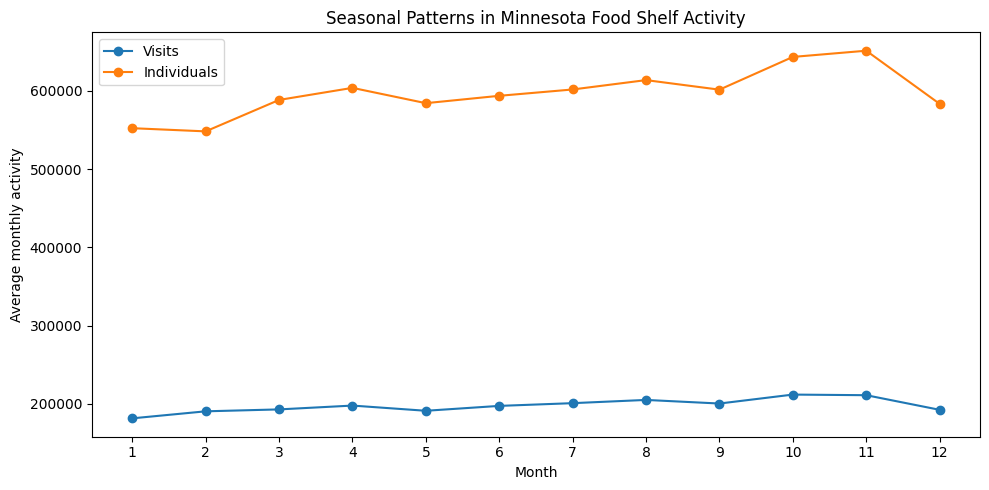

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonality.index,
    seasonality["visits"],
    marker="o",
    label="Visits"
)

ax.plot(
    seasonality.index,
    seasonality["individuals"],
    marker="o",
    label="Individuals"
)

ax.set_xlabel("Month")
ax.set_ylabel(
    "Average monthly activity"
)

ax.set_title(
    "Seasonal Patterns in Minnesota Food Shelf Activity"
)

ax.set_xticks(
    range(1, 13)
)

ax.legend()

plt.tight_layout()
plt.show()

> **What this result means:** The chart shows both visits and individuals following a similar seasonal shape — both climbing through spring/summer and peaking in fall before dropping in winter/January — reinforcing that the two metrics move together seasonally, as expected since both are different ways of counting the same underlying food-shelf usage.

### Pounds separately

> **Purpose:** Pounds distributed is on a very different scale (millions vs. hundreds of thousands) than visits/individuals, so it needs its own chart rather than being squeezed onto the same axis, where it would be invisible next to the other two metrics.

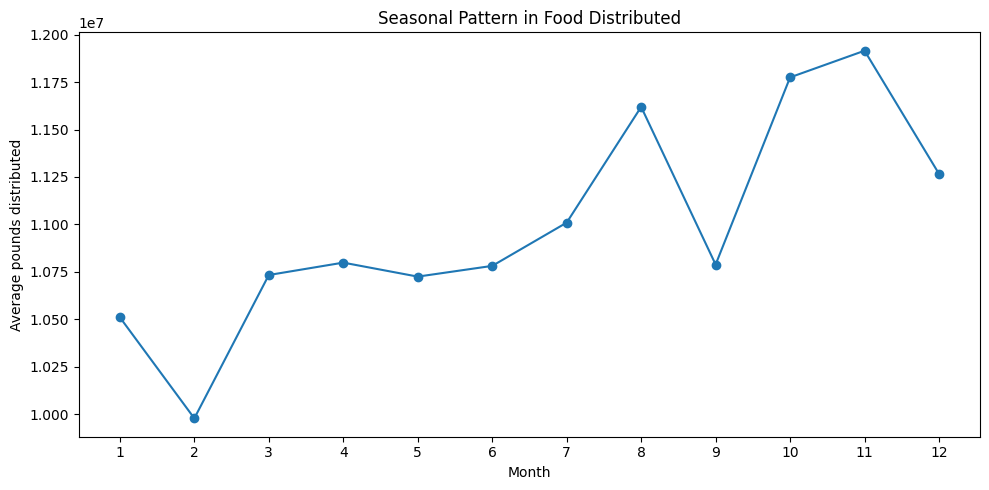

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonality.index,
    seasonality["pounds"],
    marker="o"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average pounds distributed")

ax.set_title(
    "Seasonal Pattern in Food Distributed"
)

ax.set_xticks(
    range(1, 13)
)

plt.tight_layout()
plt.show()

> **What this result means:** Pounds distributed shows the same general seasonal shape as visits and individuals — rising through the year and peaking around October-November — confirming the seasonal pattern holds across all three ways of measuring food-shelf activity, not just visit counts.

### Control for seasonality with month fixed effects

> **Purpose:** Given the seasonality confirmed above, a regression of activity change on CPI change needs to control for which quarter of the year it is — otherwise, the CPI coefficient could just be picking up a seasonal pattern that has nothing to do with prices. Quarter (rather than month) dummies are used here specifically to preserve degrees of freedom, since the dataset only has ~53-55 monthly observations and a full set of 11 month dummies would leave too few observations per parameter to estimate anything reliably.

In [ ]:
reg_data = statewide.dropna(
    subset=["cpi_pct_change", "visits_pct_change", "individuals_pct_change", "pounds_pct_change"]
).copy()

# Use quarter instead of month fixed effects: 3 dummy variables instead of 11,
# which leaves far more degrees of freedom for only 53 monthly observations.
reg_data["quarter"] = reg_data["date"].dt.quarter

model_visits = smf.ols("visits_pct_change ~ cpi_pct_change + C(quarter)", data=reg_data).fit()
print(model_visits.summary())

model_individuals = smf.ols("individuals_pct_change ~ cpi_pct_change + C(quarter)", data=reg_data).fit()
print(model_individuals.summary())

model_pounds = smf.ols("pounds_pct_change ~ cpi_pct_change + C(quarter)", data=reg_data).fit()
print(model_pounds.summary())

                            OLS Regression Results                            
Dep. Variable:      visits_pct_change   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                 -0.026
Method:                 Least Squares   F-statistic:                    0.6676
Date:                Tue, 06 Oct 2026   Prob (F-statistic):              0.618
Time:                        14:58:06   Log-Likelihood:                -191.32
No. Observations:                  54   AIC:                             392.6
Df Residuals:                      49   BIC:                             402.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           4.7225      2.633     

> **What this result means:** Even after controlling for quarter, the same-month CPI coefficient is not statistically significant for any metric (e.g., for visits: coefficient -1.52, p = 0.476), and the model's Adjusted R² is actually negative (-0.026), meaning quarter dummies plus same-month CPI explain essentially no more variation than just guessing the average. This matches the near-zero same-month correlations found earlier — there's no real same-month relationship between CPI and activity, even controlling for seasonality.

### Better: lagged regression

> **Purpose:** Since the lag analysis (Cells 31-36) found the real signal is at a 1-month lag, not same-month, this section re-runs the regression using CPI change lagged by one month instead of same-month CPI change, to see if the relationship holds up once seasonality is controlled for too.

In [ ]:
reg_data["cpi_change_lag1"] = reg_data["cpi_pct_change"].shift(1)
reg_data_lag1 = reg_data.dropna(subset=["cpi_change_lag1"]).copy()

model_visits_lag1 = smf.ols("visits_pct_change ~ cpi_change_lag1 + C(quarter)", data=reg_data_lag1).fit()
print(model_visits_lag1.summary())

model_individuals_lag1 = smf.ols("individuals_pct_change ~ cpi_change_lag1 + C(quarter)", data=reg_data_lag1).fit()
print(model_individuals_lag1.summary())

model_pounds_lag1 = smf.ols("pounds_pct_change ~ cpi_change_lag1 + C(quarter)", data=reg_data_lag1).fit()
print(model_pounds_lag1.summary())

                            OLS Regression Results                            
Dep. Variable:      visits_pct_change   R-squared:                       0.121
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     1.653
Date:                Tue, 06 Oct 2026   Prob (F-statistic):              0.176
Time:                        14:58:08   Log-Likelihood:                -178.23
No. Observations:                  53   AIC:                             366.5
Df Residuals:                      48   BIC:                             376.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.1874      2.175     

> **What this result means:** The 1-month-lag CPI coefficient for visits is 3.98 and is statistically significant at the 5% level (p = 0.024) — a real, if modest, effect: each 1-percentage-point rise in CPI is associated with roughly a 4-percentage-point rise in visits one month later. The quarter dummies themselves are not individually significant here, meaning once lagged CPI is included, no single quarter stands out. This supports the Cells 31-36 pattern: food-price increases appear to show up in food-shelf activity with roughly a one-month delay, though the relationship is still far from fully explaining month-to-month swings (R² = 0.121).

### Compact regression summary - for slides

> **Purpose:** This builds a small, slide-ready table collapsing all six regression models (3 metrics × same-month vs. 1-month-lag) down to just their CPI coefficients, so the comparison between same-month and lagged effects can be presented in one glance rather than six separate regression summaries.

In [ ]:
reg_summary = pd.DataFrame({
    "Metric": [
        "Visits",
        "Individuals",
        "Pounds"
    ],
    "Same-month coefficient": [
        model_visits.params.get(
            "cpi_pct_change", np.nan
        ),
        model_individuals.params.get(
            "cpi_pct_change", np.nan
        ),
        model_pounds.params.get(
            "cpi_pct_change", np.nan
        )
    ],
    "1-month-lag coefficient": [
        model_visits_lag1.params.get(
            "cpi_change_lag1", np.nan
        ),
        model_individuals_lag1.params.get(
            "cpi_change_lag1", np.nan
        ),
        model_pounds_lag1.params.get(
            "cpi_change_lag1", np.nan
        )
    ]
})

print(
    reg_summary.round(4)
)

        Metric  Same-month coefficient  1-month-lag coefficient
0       Visits                 -1.5245                   3.9820
1  Individuals                 -0.0294                   4.9591
2       Pounds                 -0.9076                   3.6700


> **What this result means:** Comparing the two columns side-by-side: every same-month coefficient is small/negative and not meaningfully different from zero, while every 1-month-lag coefficient is positive and meaningfully larger (Individuals: 4.96, Visits: 3.98, Pounds: 3.67). This is the key number for a slide — it directly shows the lagged relationship is consistently the stronger, more credible one across all three metrics, not just a fluke of one metric.

### Final analytical summary table

> **Purpose:** This closing table consolidates the whole Q4 price-relationship analysis — same-month correlation, best lag, and best-lag correlation — into one row per metric, intended as the final reference table for the write-up or slide.

In [ ]:
summary_table = []

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    metric_lags = lag_results[
        lag_results["metric"] == metric
    ].copy()

    best_row = metric_lags.loc[
        metric_lags["correlation"].idxmax()
    ]

    same_month = metric_lags.loc[
        metric_lags["CPI_lag_months"] == 0,
        "correlation"
    ].iloc[0]

    summary_table.append({
        "Metric": metric,
        "Same_month_corr": same_month,
        "Strongest_lag_months": int(
            best_row["CPI_lag_months"]
        ),
        "Strongest_lag_corr": best_row[
            "correlation"
        ]
    })

summary_table = pd.DataFrame(
    summary_table
)

print(
    summary_table.round(3)
)

        Metric  Same_month_corr  Strongest_lag_months  Strongest_lag_corr
0       visits           -0.016                     1               0.343
1  individuals            0.074                     1               0.389
2       pounds           -0.080                     1               0.260


> **What this result means:** The final summary confirms the overall Q4 finding in one place: for all three metrics, the same-month correlation with CPI is close to zero, but a clear, moderate positive correlation (0.26-0.39) emerges at a 1-month lag. Headline takeaway: Minnesota food-shelf need does not spike in the same month food prices rise, but shows a measurable increase about one month after a price increase — with the caveat (from the regression section) that this relationship, while statistically detectable, is modest in strength and should be presented as such, not as a strong predictive driver.

###

> **Note:** This is an empty heading with no title text and nothing beneath it — likely a leftover placeholder from editing. Consider deleting it or giving it a real title if another section was intended to go here before final submission.